# EDA

**How did recorded tip percentages differ between February and December for card-paid NYC yellow taxi trips in 2022–2024?** This notebook describes those six months and motivates the later prediction experiment that will evaluate whether a month indicator improves accuracy on February and December 2025.

Run **clean data** first. Each month contributes 250,000 trips to the tipping analysis, so the pooled estimates give each year equal weight within February and within December.

The charts are displayed below and exported as PNGs to `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
YEARS = [2022, 2023, 2024]
MONTH_NAMES = ["Feb", "Dec"]
COLORS = {"Feb": "#F7879A", "Dec": "#89CFF0"}
PERIODS = [f"{year}-{month}" for year in YEARS for month in ("02", "12")]

columns = [
    "year", "month_name", "tip_pct_total", "tip_pct", "tip_amount", "tip_over_100_pct",
    "pu_borough", "hour", "fare_amount", "trip_distance", "duration_min", "is_airport",
]
trips = pd.concat(
    [pd.read_parquet(DATA / "sample" / f"sample_{month}.parquet", columns=columns)
     for month in PERIODS],
    ignore_index=True,
)
trips["zero_tip"] = trips["tip_amount"].eq(0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## Tip distribution and choice of outcome

The primary outcome is 100 × recorded tip ÷ (recorded total − recorded tip). The table compares how strongly recorded tips bunch near the 20% rate using two denominators. Bunching offers evidence about a possible preset. The histogram displays 0% to 50% and calculates each bin as a share of all trips in its month group.

,Share within 0.5 percentage points of 20%
Full pre-tip charge,52.96
Fare alone,1.67


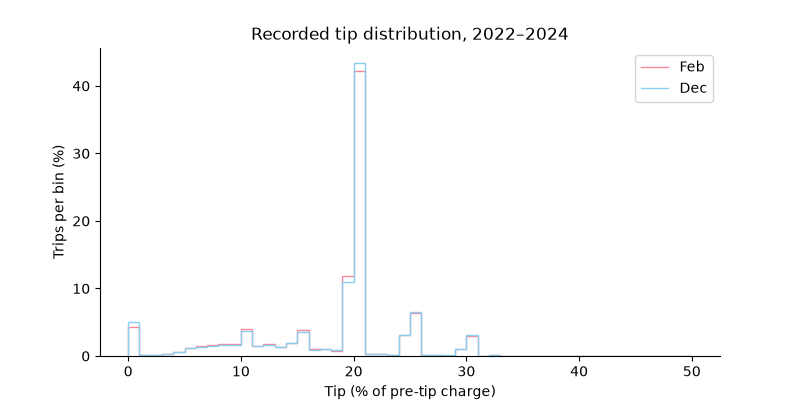

In [2]:
preset_check = pd.Series({
    "Full pre-tip charge": trips["tip_pct_total"].between(19.5, 20.5).mean() * 100,
    "Fare alone": trips["tip_pct"].between(19.5, 20.5).mean() * 100,
}, name="Share within 0.5 percentage points of 20%")
display(preset_check.round(2).to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(0, 51)
for month in MONTH_NAMES:
    values = trips.loc[trips["month_name"].eq(month), "tip_pct_total"]
    counts, edges = np.histogram(values, bins=bins)
    ax.stairs(100 * counts / len(values), edges, label=month, color=COLORS[month])

ax.set(xlabel="Tip (% of pre-tip charge)", ylabel="Trips per bin (%)",
       title="Recorded tip distribution, 2022–2024")
ax.legend()
fig.savefig(FIGURES / "tip_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## Tipping by month and year

Compare the mean and zero-tip share within each year. A zero in TLC records is a zero recorded tip. Any cash tip is unobserved. The pooled fare-based gap is shown as a sensitivity check on the outcome definition.

Pooled fare-based gap (Dec − Feb): -0.10 pp


month_name,Feb,Dec,Dec_minus_Feb_pp
year,,,
2022,18.70,18.63,-0.07
2023,17.77,17.96,0.19
2024,17.74,17.80,0.06
Pooled,18.07,18.13,0.06


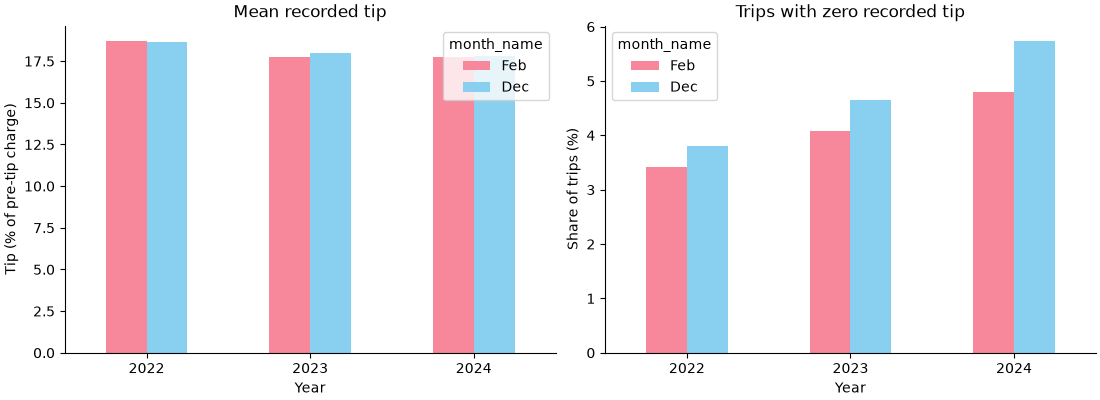

In [3]:
yearly = trips.groupby(["year", "month_name"]).agg(
    mean_tip_pct=("tip_pct_total", "mean"),
    zero_tip_share=("zero_tip", "mean"),
)
yearly["zero_tip_share"] *= 100
mean_tips = yearly["mean_tip_pct"].unstack()[MONTH_NAMES]
mean_gap = mean_tips.assign(Dec_minus_Feb_pp=mean_tips["Dec"] - mean_tips["Feb"])
mean_gap.loc["Pooled"] = mean_gap.mean()
display(mean_gap.astype(float).round(2))

fare_means = trips.groupby("month_name")["tip_pct"].mean()
print(f"Pooled fare-based gap (Dec − Feb): {fare_means['Dec'] - fare_means['Feb']:.2f} pp")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric, title, ylabel in zip(
    axes, ["mean_tip_pct", "zero_tip_share"],
    ["Mean recorded tip", "Trips with zero recorded tip"],
    ["Tip (% of pre-tip charge)", "Share of trips (%)"],
):
    yearly[metric].unstack()[MONTH_NAMES].plot.bar(
        ax=ax, color=[COLORS[month] for month in MONTH_NAMES], rot=0
    )
    ax.set(title=title, xlabel="Year", ylabel=ylabel)
fig.savefig(FIGURES / "tips_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

## Pickup location and time

Borough and hour summarize how tipping varies with where and when the ride starts. These comparisons motivate the pickup-zone-and-hour prediction benchmark. The borough chart compares all five NYC pickup boroughs, pooling 2022–2024. The table shows the sample size behind each bar. Staten Island has relatively few sampled trips, so its averages can be sensitive to individual rides.

month_name,Feb trips,Dec trips
pu_borough,,
Manhattan,690443,680526
Queens,54583,63343
Brooklyn,3955,4922
Bronx,986,1180
Staten Island,32,23


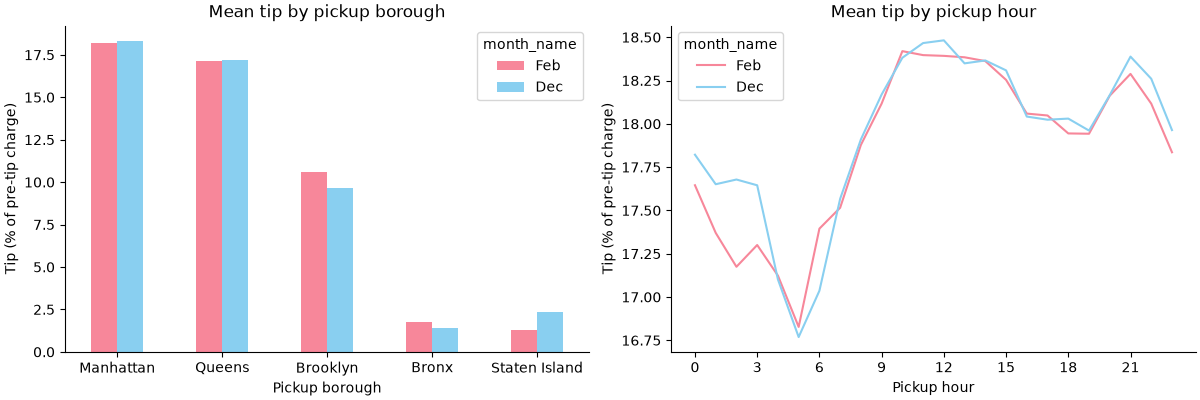

In [4]:
borough = trips.groupby(["pu_borough", "month_name"])["tip_pct_total"]
borough_counts = borough.size().unstack().reindex(columns=MONTH_NAMES)
shown_boroughs = ["Manhattan", "Queens", "Brooklyn", "Bronx", "Staten Island"]
borough_means = borough.mean().unstack().reindex(index=shown_boroughs, columns=MONTH_NAMES)
display(borough_counts.reindex(shown_boroughs).rename(columns={"Feb": "Feb trips", "Dec": "Dec trips"}))
hour_means = trips.groupby(["hour", "month_name"])["tip_pct_total"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
borough_means.plot.bar(ax=axes[0], color=[COLORS[month] for month in MONTH_NAMES], rot=0)
hour_means[MONTH_NAMES].plot(ax=axes[1], color=[COLORS[month] for month in MONTH_NAMES])
axes[0].set(title="Mean tip by pickup borough", xlabel="Pickup borough",
            ylabel="Tip (% of pre-tip charge)")
axes[1].set(title="Mean tip by pickup hour", xlabel="Pickup hour",
            ylabel="Tip (% of pre-tip charge)", xticks=range(0, 24, 3))
fig.savefig(FIGURES / "tips_by_borough_and_hour.png", dpi=150, bbox_inches="tight")
plt.show()

## Trip mix and data selection

The trip characteristics table describes the cleaned sample. Payment mix uses all raw records in each source file. Daily volume uses all eligible cleaned card-paid trips and describes taxi activity.

,mean_fare,mean_distance_miles,mean_duration_minutes,airport_share_pct
month_name,,,,
Feb,16.30,3.17,15.83,8.39
Dec,18.53,3.35,18.37,10.01


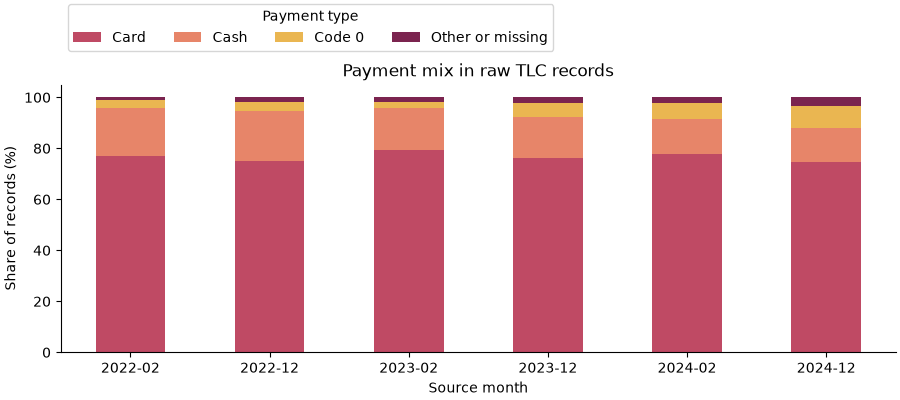

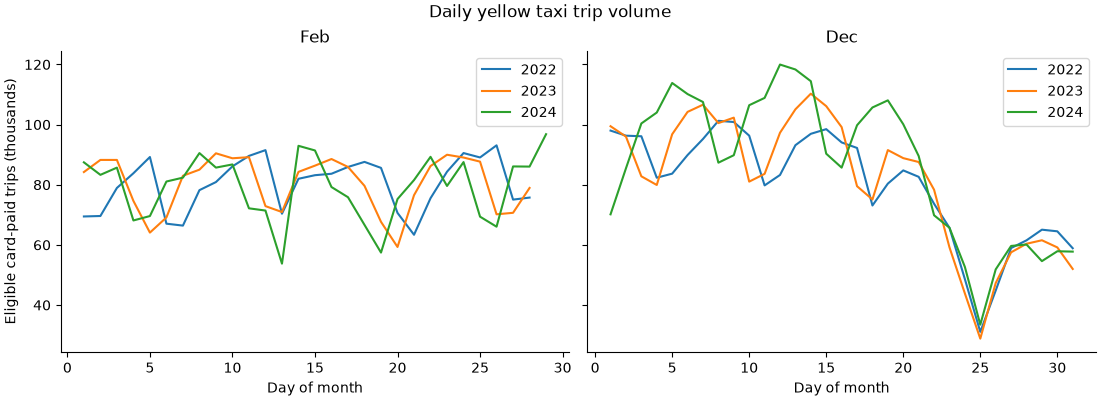

In [5]:
trip_mix = trips.groupby("month_name").agg(
    mean_fare=("fare_amount", "mean"),
    mean_distance_miles=("trip_distance", "mean"),
    mean_duration_minutes=("duration_min", "mean"),
    airport_share_pct=("is_airport", "mean"),
).loc[MONTH_NAMES]
trip_mix["airport_share_pct"] *= 100
display(trip_mix.astype(float).round(2))

payment = pd.read_csv(DATA / "processed" / "eda_payment_counts.csv")
payment = payment.pivot(index="month", columns="payment", values="trips").reindex(PERIODS)
payment = payment.reindex(columns=["Card", "Cash", "Code 0", "Other or missing"]).fillna(0)
payment_share = 100 * payment.div(payment.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
payment_share.plot.bar(ax=ax, stacked=True, rot=0, color=["#bf4a64", "#e78569", "#eab651", "#7b244f"])
ax.set(title="Payment mix in raw TLC records", xlabel="Source month",
       ylabel="Share of records (%)")
ax.legend(title="Payment type", loc="lower left", bbox_to_anchor=(0, 1.10), ncol=4)
fig.savefig(FIGURES / "payment_mix.png", dpi=150, bbox_inches="tight")
plt.show()

daily = pd.read_csv(DATA / "processed" / "eda_daily_volume.csv", parse_dates=["date"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, name, number in zip(axes, MONTH_NAMES, (2, 12)):
    for year in YEARS:
        days = daily.loc[daily["month"].eq(f"{year}-{number:02d}")]
        ax.plot(days["date"].dt.day, days["trips"] / 1000, label=year)
    ax.set(title=name, xlabel="Day of month")
    ax.legend()
axes[0].set_ylabel("Eligible card-paid trips (thousands)")
fig.suptitle("Daily yellow taxi trip volume")
fig.savefig(FIGURES / "daily_trip_volume.png", dpi=150, bbox_inches="tight")
plt.show()

## Sensitivity to tips above 100%

Compare the primary result across all eligible sample trips and after excluding flagged tips above 100% of the full pre-tip charge. The pooled rows weight the three years equally in both comparisons.

In [6]:
flagged = trips.groupby(["year", "month_name"])["tip_over_100_pct"].sum().unstack()
restricted = trips.loc[~trips["tip_over_100_pct"]]
restricted_means = restricted.groupby(["year", "month_name"])["tip_pct_total"].mean().unstack()
restricted_gap = restricted_means["Dec"] - restricted_means["Feb"]
sensitivity = pd.DataFrame({
    "Feb trips flagged": flagged["Feb"],
    "Dec trips flagged": flagged["Dec"],
    "Gap with all tips (pp)": mean_gap.loc[YEARS, "Dec_minus_Feb_pp"],
    "Gap excluding flagged tips (pp)": restricted_gap,
})
gap_columns = ["Gap with all tips (pp)", "Gap excluding flagged tips (pp)"]
sensitivity.loc["Pooled"] = {
    "Feb trips flagged": flagged["Feb"].sum(),
    "Dec trips flagged": flagged["Dec"].sum(),
    **sensitivity[gap_columns].mean().to_dict(),
}
display(sensitivity.round(3))

pooled = mean_gap.loc["Pooled"]
print(f"Pooled mean tip: {pooled['Feb']:.2f}% in February and {pooled['Dec']:.2f}% in December.")
print(f"December minus February: {pooled['Dec_minus_Feb_pp']:+.3f} pp with all eligible tips "
      f"and {restricted_gap.mean():+.3f} pp after excluding flagged tips.")

Pooled mean tip: 18.07% in February and 18.13% in December.
December minus February: +0.057 pp with all eligible tips and +0.035 pp after excluding flagged tips.


,Feb trips flagged,Dec trips flagged,Gap with all tips (pp),Gap excluding flagged tips (pp)
year,,,,
2022,193,212,-0.072,-0.094
2023,118,144,0.187,0.180
2024,119,176,0.056,0.021
Pooled,430,532,0.057,0.035
